# EUV projector and pupil

Notebook 156 (EUV multilayers and reflective masks) built the mask: a
multilayer mirror with an absorber on top, lit at 6°. This notebook looks at
the optics between mask and wafer:

- **The geometry at the mask.** The illumination comes in and the image
  goes out on the same side of a reflective mask, so their cones must not
  overlap. That ties the chief ray angle (CRA) to the mask-side NA, and at
  NA 0.55 it forces either a larger CRA, with more mask 3D effects, or the
  **anamorphic** projector of the high-NA scanners: 4x across the scan, 8x
  along it (`litho.euv.min_cra()`, `mask_cones()`, a `Projector` with
  `magnification=(4, 8)` and `ReflectiveMask`).
- **Depth of focus** at the larger NA.
- **The obscured pupil.** The high-NA projection optics have a hole in
  the middle of their pupil; diffraction orders that fall into it are lost
  (`euv.obscured_pupil()`).
- **Multilayers on the projection mirrors.** A two-mirror Schwarzschild
  objective of the kind used in the EUV micro-exposure tools (NA 0.3, 5x),
  ray traced with the off-axis tools of notebook 155 (off-axis mirrors and nodal aberrations), coated with Mo/Si of one period or graded, and its
  Jones pupil from the polarization ray trace of notebook 20 (polarization ray tracing) put into the image simulation of notebook 38 (Jones pupils).

The six-mirror projectors of EUV scanners are left for a later notebook;
the two-mirror objective has all the pupil effects in a small system.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import off_axis as oa, sketch
from pyoptics.litho import (Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, euv,
                            jones_pupil, lens, metrics)

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()
BLUE, ORANGE, GREEN, YELLOW, RED, PURPLE, GREY = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b",
                                                  "#8a5cc2", "#888888")
LAM = euv.EUV_WAVELENGTH
DEG = np.pi/180

## 1. The cones at the mask

Seen from above the mask, the reflected (imaging) cone is centred on the
direction cosine $\sin(\mathrm{CRA})$ in y, the incident cone, reversed, on
$-\sin(\mathrm{CRA})$. Their radii are NA/M (and σ NA/M for the source). They
stay apart as long as $\sin(\mathrm{CRA}) \ge (1+\sigma)\,\mathrm{NA}/(2M_y)$
(`min_cra()`), plus some room for the mirrors that fold the beams
next to each other.

                        mask-side NA (x, y)   min CRA (sigma 1)
NA 0.33, 4x             0.0825, 0.0825          4.73°
NA 0.55, 4x             0.1375, 0.1375          7.90°
NA 0.55, 4x/8x          0.1375, 0.0688          3.94°

mask field 104 x 132 mm: wafer field 26 x 33 mm at 4x, 26 x 16.5 mm at 4x/8x


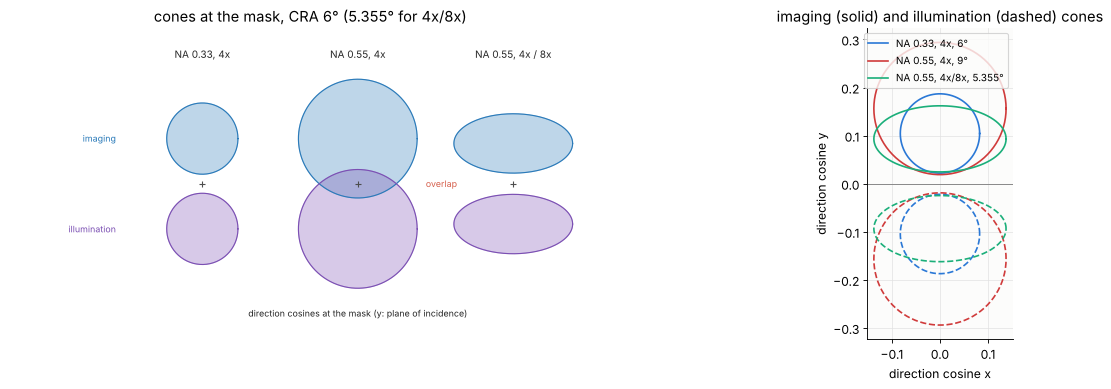

In [2]:
print("                        mask-side NA (x, y)   min CRA (sigma 1)")
for name, NA, M in (("NA 0.33, 4x", 0.33, (4, 4)), ("NA 0.55, 4x", 0.55, (4, 4)),
                    ("NA 0.55, 4x/8x", 0.55, (4, 8))):
    print(f"{name:18s}      {NA/M[0]:.4f}, {NA/M[1]:.4f}          {euv.min_cra(NA, M[1]):.2f}°")
print(f"\nmask field 104 x 132 mm: wafer field {104/4:.0f} x {132/4:.0f} mm at 4x, "
      f"{104/4:.0f} x {132/8:.1f} mm at 4x/8x")

fig, axes = plt.subplots(1, 2, figsize=(17, 5.0), gridspec_kw={"width_ratios": [1.25, 1]})
sketch.euv_layout(axes[0], "anamorphic", title="cones at the mask, CRA 6° (5.355° for 4x/8x)")
ax = axes[1]
for (name, NA, M, cra), col in zip((("NA 0.33, 4x, 6°", 0.33, 4, 6.0), ("NA 0.55, 4x, 9°", 0.55, 4, 9.0),
                                    ("NA 0.55, 4x/8x, 5.355°", 0.55, (4, 8), 5.355)), (BLUE, RED, GREEN)):
    img, ill = euv.mask_cones(NA, M, cra)
    ax.plot(*img.T, color=col, label=name)
    ax.plot(*ill.T, color=col, ls="--")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_aspect("equal"); ax.set_xlabel("direction cosine x"); ax.set_ylabel("direction cosine y")
ax.legend(fontsize=9, loc="upper right")
ax.set_title("imaging (solid) and illumination (dashed) cones")
fig.tight_layout()

At NA 0.33 and 4x the 6° of today's scanners leave about a degree of room.
At NA 0.55 and 4x the cones need at least 7.9°, in practice about 9°. An
anamorphic projector halves the mask-side NA in y (8x), and 5.355° fit
again. The price: a mask of the usual 104 × 132 mm now prints 26 × 16.5 mm
on the wafer, half the field, so a full field takes two exposures and two
masks (stitching). Across the scan (x) the reduction stays 4x and the
field stays 26 mm wide.

## 2. The mask at NA 0.55: a larger CRA or an anamorphic projector

The mask 3D effects of notebook 156 (EUV multilayers and reflective masks)
grow with the CRA and with the mask-side NA, both in y. Lines and spaces
(TaBN, 60 nm) at NA 0.55 with a dipole, for an isotropic 4x projector at
9° and the anamorphic one at 5.355°. The layouts are given at wafer scale;
`ReflectiveMask` makes the mask pitch 4 times longer in x and 8 times in y.

28 focus series in 23 s
NA 0.55, 4x, CRA 9°          y: NILS 1.98-2.11, best focus  -24.0 to  -5.1 nm, shift -0.00 to 0.00 nm, telecentricity -0 to 0 mrad
NA 0.55, 4x, CRA 9°          x: NILS 1.40-3.49, best focus    1.3 to   4.1 nm, shift 1.28 to 2.09 nm, telecentricity -193 to -105 mrad
NA 0.55, 4x/8x, CRA 5.355°   y: NILS 1.98-2.16, best focus  -23.4 to  -4.8 nm, shift -0.00 to 0.00 nm, telecentricity -0 to 0 mrad
NA 0.55, 4x/8x, CRA 5.355°   x: NILS 2.54-3.04, best focus  -12.1 to  -0.8 nm, shift 1.23 to 1.37 nm, telecentricity -30 to -19 mrad


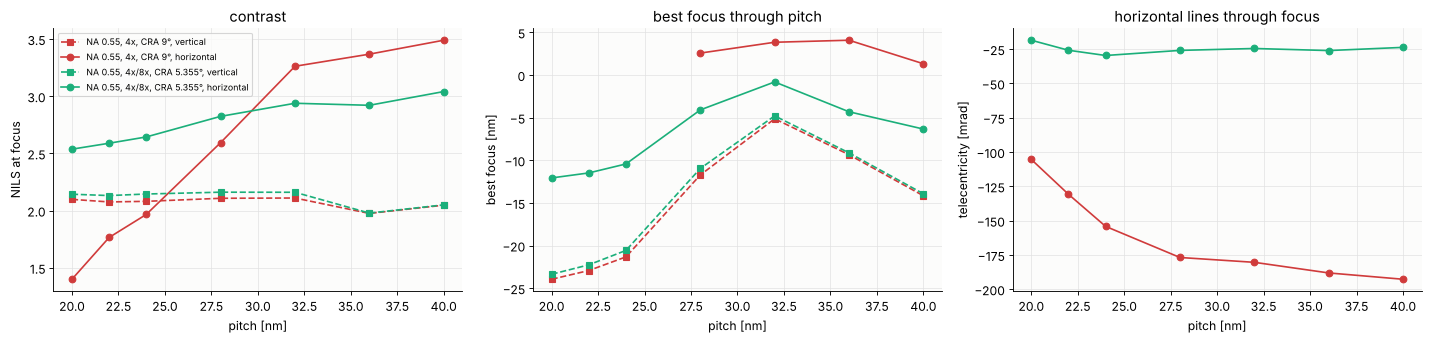

In [3]:
ml_6 = euv.Multilayer.design(LAM, 6*DEG)


def lines(NA, M, cra, pitch, orientation, mask=None, sigma=(0.9, 0.55), obscuration=0.0):
    """Dark 1:1 lines on a reflective TaBN mask with a dipole across the lines."""
    if mask is None:
        mask = euv.ReflectiveMask([("TaBN", 60.0)], euv.Multilayer.design(LAM, cra*DEG), cra=cra)
    P = Projector(NA, LAM, magnification=M,
                  apodization=euv.obscured_pupil(obscuration) if obscuration else None)
    axis = "x" if orientation == "y" else "y"
    return LithoSimulation(MaskLayout.lines_spaces(pitch, pitch/2, orientation=orientation), mask,
                           Illumination.dipole(sigma[0], sigma[1], axis=axis, n_samples=21), P)


def threshold_to_size(u, I, center, cd):
    """Threshold at which the dark line prints at cd."""
    ts = np.linspace(I.min() + 1e-3, I.max() - 1e-3, 400)
    e = np.array([metrics.threshold_cd(u, I, th, center) - cd for th in ts])
    ok = np.isfinite(e)
    if ok.sum() < 2 or e[ok].min() > 0 or e[ok].max() < 0:
        return np.nan
    o = np.argsort(e[ok])
    return float(np.interp(0.0, e[ok][o], ts[ok][o]))


foci = np.linspace(-40, 40, 17)


def analyse(sim, pitch):
    """NILS at focus, best focus (NILS), shift at focus and its slope through
    focus, at the threshold that sizes the line at focus 0."""
    u, c = sim.cut_coordinates(201)[:2]
    I = sim._cuts(201, 1.0, None, foci, 0.0)[1]
    th = threshold_to_size(u, I[len(foci)//2], c, pitch/2)
    nils = np.array([metrics.nils_at_threshold(u, Ii, th, c) for Ii in I])
    centre = np.array([euv.feature_center(u, Ii, th, c) for Ii in I]) - c
    ok = np.isfinite(centre) & (abs(foci) <= 20)
    slope = np.polyfit(foci[ok], centre[ok], 1)[0] if ok.sum() > 2 else np.nan
    return nils[len(foci)//2], metrics.best_focus(foci, nils, n_fit=9), centre[len(foci)//2], 1e3*slope


t0 = time.time()
configs = (("NA 0.55, 4x, CRA 9°", 4, 9.0, RED), ("NA 0.55, 4x/8x, CRA 5.355°", (4, 8), 5.355, GREEN))
pitches = np.array([20.0, 22.0, 24.0, 28.0, 32.0, 36.0, 40.0])
res = {}
for name, M, cra, col in configs:
    for orient in ("y", "x"):
        res[name, orient] = np.array([analyse(lines(0.55, M, cra, p, orient), p) for p in pitches])
print(f"{len(res)*len(pitches)} focus series in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
for name, M, cra, col in configs:
    for orient, ls, mk in (("y", "--", "s"), ("x", "-", "o")):
        r = res[name, orient]
        lab = f"{name}, {'vertical' if orient == 'y' else 'horizontal'}"
        axes[0].plot(pitches, r[:, 0], ls, marker=mk, color=col, label=lab)
        axes[1].plot(pitches, r[:, 1], ls, marker=mk, color=col, label=lab)
        if orient == "x":
            axes[2].plot(pitches, r[:, 3], ls, marker=mk, color=col, label=lab)
axes[0].set_ylabel("NILS at focus"); axes[1].set_ylabel("best focus [nm]")
axes[2].set_ylabel("telecentricity [mrad]")
for ax in axes:
    ax.set_xlabel("pitch [nm]")
axes[0].legend(fontsize=8)
axes[0].set_title("contrast"); axes[1].set_title("best focus through pitch")
axes[2].set_title("horizontal lines through focus")
fig.tight_layout()
for key, r in res.items():
    print(f"{key[0]:28s} {key[1]}: NILS {np.nanmin(r[:, 0]):.2f}-{np.nanmax(r[:, 0]):.2f}, "
          f"best focus {np.nanmin(r[:, 1]):6.1f} to {np.nanmax(r[:, 1]):5.1f} nm, "
          f"shift {np.nanmin(r[:, 2]):.2f} to {np.nanmax(r[:, 2]):.2f} nm, "
          f"telecentricity {np.nanmin(r[:, 3]):.0f} to {np.nanmax(r[:, 3]):.0f} mrad")

The vertical lines (pitch along x, where both projectors have 4x) behave the
same in both. The horizontal lines are where the projectors differ. At 9°
and 4x the dense horizontal lines lose a third of their NILS (1.4 against
2.1 for vertical lines at 20 nm pitch), their best focus moves from that of the
vertical lines by up to 25 nm, and they walk sideways through focus by 100
to 190 mrad, 1 to 2 nm per 10 nm of focus. (Above 30 nm pitch the
horizontal lines at 9° have more NILS than the vertical ones: shadowing
does not only take contrast, it also changes the balance and phase of the
orders, which can help some pitches.) With 8x in y the angles at the mask are
halved: the horizontal lines keep more NILS than the vertical ones, the
H-V best focus difference falls to about 10 nm, and the telecentricity
error to 20 to 30 mrad, close to NA 0.33.

## 3. Depth of focus

The depth of focus scales with $\lambda/\mathrm{NA}^2$: 124 nm at NA 0.33,
45 nm at NA 0.55. At about the same $k_1$ (0.39 and 0.41) the larger NA
prints lines 1.6 times smaller with 2.8 times less focus range. The
resists are therefore thinner (20 to 30 nm), which costs absorbed photons,
the subject of notebook 158 (EUV stochastics and flare).

NA 0.33: lambda/NA^2 = 124 nm, focus range with NILS >= 80 % of the peak: -120 to 30 nm


NA 0.55: lambda/NA^2 = 45 nm, focus range with NILS >= 80 % of the peak: -45 to 0 nm


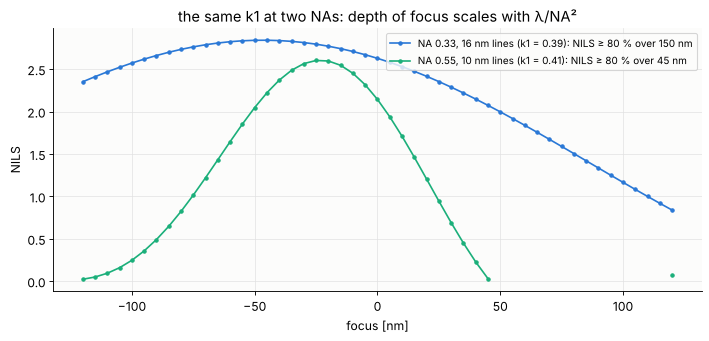

In [4]:
foci_w = np.linspace(-120, 120, 49)
fig, ax = plt.subplots(figsize=(9, 4.4))
for NA, M, cra, pitch, col in ((0.33, 4, 6.0, 32.0, BLUE), (0.55, (4, 8), 5.355, 20.0, GREEN)):
    sim = lines(NA, M, cra, pitch, "y")
    u, c = sim.cut_coordinates(201)[:2]
    I = sim._cuts(201, 1.0, None, foci_w, 0.0)[1]
    th = threshold_to_size(u, I[len(foci_w)//2], c, pitch/2)
    nils = np.array([metrics.nils_at_threshold(u, Ii, th, c) for Ii in I])
    good = foci_w[nils >= 0.8*np.nanmax(nils)]
    ax.plot(foci_w, nils, "o-", ms=3, color=col,
            label=f"NA {NA}, {pitch/2:.0f} nm lines (k1 = {pitch/2*NA/LAM:.2f}): "
                  f"NILS ≥ 80 % over {good.max() - good.min():.0f} nm")
    print(f"NA {NA}: lambda/NA^2 = {LAM/NA**2:.0f} nm, focus range with NILS >= 80 % of the peak: "
          f"{good.min():.0f} to {good.max():.0f} nm")
ax.set_xlabel("focus [nm]"); ax.set_ylabel("NILS"); ax.legend(fontsize=9)
ax.set_title("the same k1 at two NAs: depth of focus scales with λ/NA²")
fig.tight_layout()

The NILS stays at its peak over about 150 nm of focus at NA 0.33 and over
45 nm at NA 0.55 (mask 3D effects shift the window towards negative focus).

## 4. The obscured pupil

Mirrors with large angles of incidence lose reflectance and gain
polarization effects (section 5). The high-NA projection optics therefore
use mirrors with a hole, and the last mirror before the wafer blocks the
centre of the pupil: a **central obscuration**, of the order of 20 % of the
pupil radius. A dipole for dense lines puts its poles at σ ≈ 0.75; at the
pitch where the first order of each pole lands in the centre of the pupil,
$p = \lambda/(\mathrm{NA}\,\sigma)$ ≈ 33 nm, that order is blocked. The
image of vertical lines at NA 0.55 (a thin mask; the effect is that of
the pupil) for obscurations of 0, 0.2 and 0.3 of the pupil radius:

66 images in 0 s


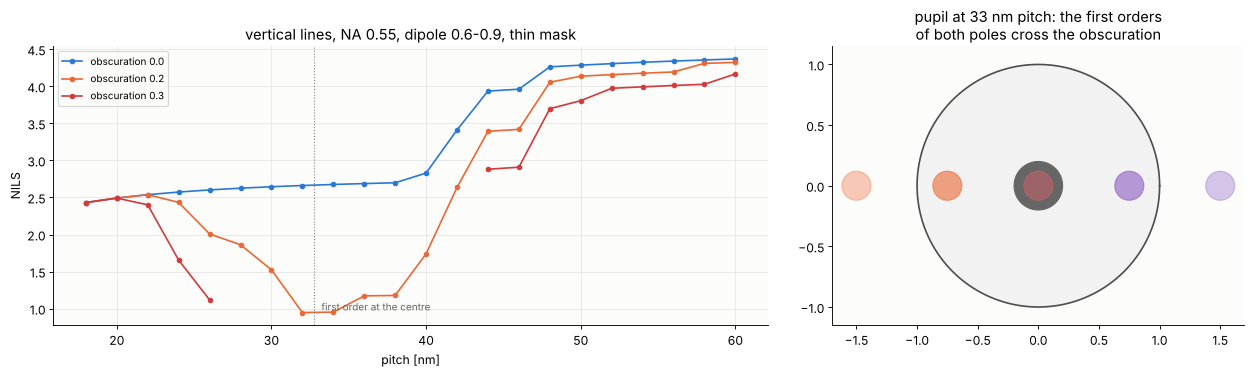

In [5]:
obscurations = (0.0, 0.2, 0.3)
pitches_o = np.arange(18.0, 61.0, 2.0)
nils_o = {}
t0 = time.time()
for obs in obscurations:
    vals = []
    for p in pitches_o:
        sim = lines(0.55, (4, 8), 5.355, p, "y", mask=ThinMask.binary(), sigma=(0.9, 0.6), obscuration=obs)
        u, c = sim.cut_coordinates(201)[:2]
        I = sim.cut(201)[1]
        vals.append(metrics.nils_at_threshold(u, I, threshold_to_size(u, I, c, p/2), c))
    nils_o[obs] = np.array(vals)
print(f"{len(obscurations)*len(pitches_o)} images in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for obs, col in zip(obscurations, (BLUE, ORANGE, RED)):
    ax.plot(pitches_o, nils_o[obs], "o-", color=col, ms=4, label=f"obscuration {obs:.1f}")
sigma_c = 0.75
p_hit = LAM/(0.55*sigma_c)
ax.axvline(p_hit, color="0.5", ls=":", lw=1)
ax.text(p_hit + 0.5, ax.get_ylim()[0] + 0.2, "first order at the centre", fontsize=9, color="0.4")
ax.set_xlabel("pitch [nm]"); ax.set_ylabel("NILS"); ax.legend(fontsize=9)
ax.set_title("vertical lines, NA 0.55, dipole 0.6-0.9, thin mask")
ax = axes[1]
t = np.linspace(0, 2*np.pi, 200)
ax.fill(np.cos(t), np.sin(t), color="0.95")
ax.plot(np.cos(t), np.sin(t), color="0.3")
ax.fill(0.2*np.cos(t), 0.2*np.sin(t), color="0.4")
for s_x, col in ((sigma_c, PURPLE), (-sigma_c, ORANGE)):
    for m in (-1, 0, 1):
        x0 = s_x + m*LAM/(p_hit*0.55)
        if abs(x0) < 1.6:
            ax.add_patch(plt.Circle((x0, 0), 0.12, color=col, alpha=0.6 if m == 0 else 0.35))
ax.set_aspect("equal"); ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.15, 1.15)
ax.set_title(f"pupil at {p_hit:.0f} nm pitch: the first orders\nof both poles cross the obscuration")
ax.grid(False)
fig.tight_layout()

Without obscuration the NILS rises smoothly with the pitch. With 0.2 a
band of **forbidden pitches** opens around 33 nm, where the first orders of
both poles fall into the hole and the image keeps only the zero orders
and the weak edges of the poles: the NILS falls from 2.7 to 1. With 0.3
the band is wider, and between 26 and 42 nm the lines do not print at
all (no threshold gives the target CD). The design rules and the source
optimization of high-NA layers avoid these pitches, or the source moves
its poles so that the orders of the pitches that are needed miss the hole.

## 5. Multilayers on the projection mirrors

The Schwarzschild objective (`euv.schwarzschild_objective()`): a small
convex mirror M1, the aperture stop, sends the light back to a large
concave mirror M2 around the incoming beam, and M2 focuses it past M1 onto
the wafer. The two mirrors are concentric, the object distance sets 5x,
conic constants remove the third order spherical aberration and coma
(`off_axis.solve_conics()`, notebook 155, off-axis mirrors and nodal aberrations), and aspheric terms fitted to the ray traced OPD make it
diffraction limited over a field of 0.1 mm. M1 blocks the centre of the
returning beam and M2 needs a hole for the incoming one: the obscuration
comes with the design (`euv.obscuration()`).

System(wavelength=1.35e-05, stop_index=0, object_distance=93.75000000000072, max_field=0.25)
   0* Mirror(R=30.0, thickness=-80.0, n_after=None, material=None, conic=-0.0865919999999949, aspheric=(np.float64(5.541353911146557e-09), np.float64(5.967699472467521e-10), np.float64(3.5946341324801816e-11), np.float64(-5.050947443663212e-13)), semi_diameter=5.625000000000004) n'=1.000000
   1  Mirror(R=110.0, thickness=134.74996699243826, n_after=None, material=None, conic=-0.00313644824860378, aspheric=(np.float64(2.6038707943366792e-12), np.float64(1.2744997646913781e-14), np.float64(7.984302630433885e-18), np.float64(-1.470870516454249e-21)), semi_diameter=None) n'=1.000000
NA 0.300, magnification -0.200, object distance 93.8 mm, image 54.7 mm behind M1
RMS wavefront [waves] at the object heights 0, 0.125, 0.25 mm: 0.025, 0.010, 0.036
central obscuration 0.34 of the pupil radius (12 % of its area)
M1 (convex, stop) : footprint radius   5.6 mm, angles of incidence 0.0° to 14.2°
M2 (concave

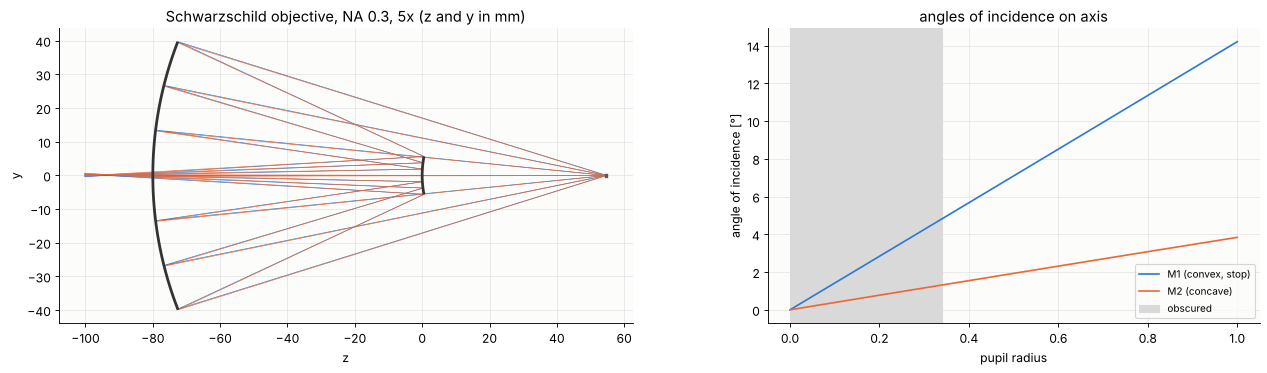

In [6]:
S = euv.schwarzschild_objective()
par = S.paraxial()
print(S)
print(f"NA {par.na:.3f}, magnification {par.magnification:.3f}, "
      f"object distance {S.object_distance:.1f} mm, image {S.surfaces[1].thickness - 80:.1f} mm behind M1")
fields = [(0.0, 0.0), (0.0, S.max_field/2), (0.0, S.max_field)]
print("RMS wavefront [waves] at the object heights 0, 0.125, 0.25 mm:",
      ", ".join(f"{np.nanstd(S.opd(f, N=48)[2]):.3f}" for f in fields))
rho_obs = euv.obscuration(S)
print(f"central obscuration {rho_obs:.2f} of the pupil radius ({100*rho_obs**2:.0f} % of its area)")
fp = oa.footprints(S, fields)
for i, f in enumerate(fp):
    r, a = euv.angles_of_incidence(S, i)
    print(f"{S.surfaces[i].label:18s}: footprint radius {f.radius:5.1f} mm, "
          f"angles of incidence {np.degrees(np.nanmin(a)):.1f}° to {np.degrees(np.nanmax(a)):.1f}°")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
oa.draw_layout(S, [(0.0, 0.0), (0.0, S.max_field)], ax=axes[0], n_rays=7, colors=[BLUE, ORANGE])
axes[0].set_title("Schwarzschild objective, NA 0.3, 5x (z and y in mm)")
for i, col in ((0, BLUE), (1, ORANGE)):
    r, a = euv.angles_of_incidence(S, i)
    axes[1].plot(np.linspace(0, 1, len(a)), np.degrees(a), color=col, label=S.surfaces[i].label)
axes[1].axvspan(0, rho_obs, color="0.85", label="obscured")
axes[1].set_xlabel("pupil radius"); axes[1].set_ylabel("angle of incidence [°]")
axes[1].legend(fontsize=9); axes[1].set_title("angles of incidence on axis")
fig.tight_layout()

The objective is diffraction limited (0.025 to 0.036 waves RMS) over its
small field, with an obscuration of 0.34 of the pupil radius (12 % of the
area), similar to the micro-exposure tools. The small convex M1 sees the
light from 0° at the centre to 14° at the rim of the pupil; M2, large
and far away, only up to 4°.

A multilayer of one period cannot serve 0° to 14°: section 2 of notebook
156 (EUV multilayers and reflective masks) showed the reflectance falling
to half at 12°. The coating of each mirror can instead be **graded**,
its period growing with the radius so that the Bragg peak follows the
local angle (`euv.graded_profile()`, a `coatings.RadialProfile` of all
layers, fitted to the designs at five angles). The polarization ray trace
(`lens.lens_jones_pupil()`, which now accepts mirrors with their own
coatings) gives the Jones pupil of both versions.

one period per mirror: transmission 0.289 to 0.537, diattenuation up to 0.281, retardance up to 37.5 milliwaves


graded multilayers: transmission 0.527 to 0.541, diattenuation up to 0.034, retardance up to 8.9 milliwaves


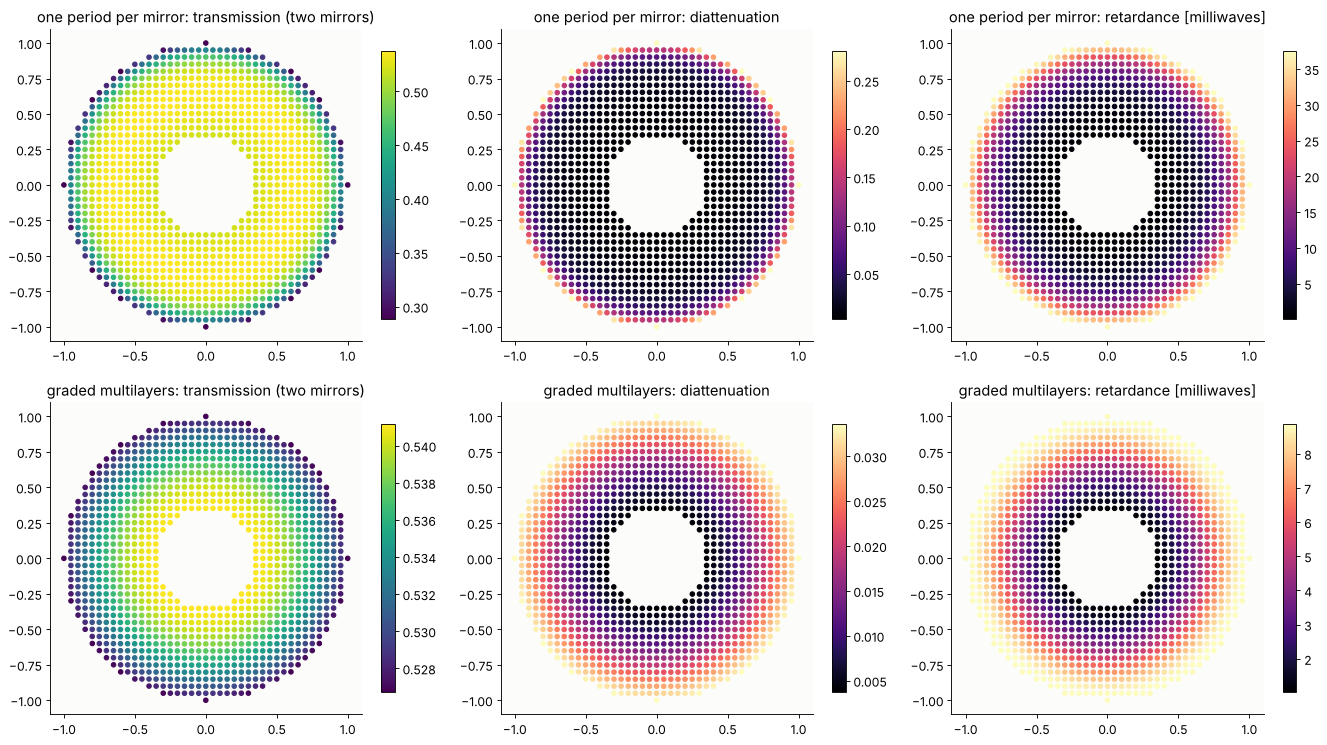

In [7]:
def coated(system, graded):
    """The objective with Mo/Si on both mirrors: one period for the mean
    angle of each mirror, or graded to the local angle."""
    out = system.copy()
    for i in (0, 1):
        r, a = euv.angles_of_incidence(system, i)
        a = a[np.linspace(0, 1, len(a)) >= rho_obs]
        r = r[np.linspace(0, 1, len(r)) >= rho_obs]
        if graded:
            mli = euv.Multilayer.design(LAM, float(a[0]))
            out.surfaces[i].coating = mli.coating(euv.graded_profile(mli, r, a, angle=float(a[0])))
        else:
            out.surfaces[i].coating = euv.Multilayer.design(LAM, float(np.mean(a))).coating()
    return out


pupils = {}
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
for k, (name, graded) in enumerate((("one period per mirror", False), ("graded multilayers", True))):
    L = lens.lens_jones_pupil(coated(S, graded), (0.0, 0.0), N=41, normalize=False)
    keep = np.hypot(L.P_x, L.P_y) >= rho_obs
    d = jones_pupil.decompose(L.J)
    T = d["transmission"]
    dia = np.hypot(d["diattenuation"][0], d["diattenuation"][1])
    ret = np.hypot(d["retardance"][0], d["retardance"][1])
    pupils[name] = (L, d)
    for ax, val, lab, cmap in ((axes[k, 0], T, "transmission (two mirrors)", "viridis"),
                               (axes[k, 1], dia, "diattenuation", "magma"),
                               (axes[k, 2], 1e3*ret, "retardance [milliwaves]", "magma")):
        sc = ax.scatter(L.P_x[keep], L.P_y[keep], c=val[keep], s=16, cmap=cmap)
        fig.colorbar(sc, ax=ax, shrink=0.8)
        ax.set_aspect("equal"); ax.set_title(f"{name}: {lab}"); ax.grid(False)
    print(f"{name}: transmission {T[keep].min():.3f} to {T[keep].max():.3f}, "
          f"diattenuation up to {dia[keep].max():.3f}, retardance up to {1e3*ret[keep].max():.1f} milliwaves")
fig.tight_layout()

With one period per mirror (designed for the mean angle on the
unobscured part), the pupil transmits 54 % in the middle and 29 % at the
rim: an apodization of almost a factor two, a diattenuation of up to 28 %
(p reflects less than s near the edge of the band) and a radial
retardance of up to 0.04 waves. Graded multilayers flatten the
transmission to 53 to 54 % and cut diattenuation and retardance by a
factor of eight and four. Two mirrors transmit 54 %; the six of a scanner
projector about 14 %, the illuminator and the mask take most of the rest.

What do these pupils do to the image? The traced pupils go into the
projector as a fitted `PhysicalJonesPupil` and apodization Zernikes,
with the obscuration. Polarized dipoles make the polarization visible: TE
(E along the lines) and TM (E across).

In [8]:
def projector_from_jones(L, d, NA=0.3, obscuration=rho_obs):
    """Projector with the polarization (retardance and diattenuation) and the
    apodization of a traced Jones pupil and the central obscuration."""
    keep = np.hypot(L.P_x, L.P_y) >= obscuration
    phys, scalar = jones_pupil.PhysicalJonesPupil.fit(L.P_x[keep], L.P_y[keep], L.J[keep], n_terms=16)
    amp = np.sqrt(d["transmission"][keep]/d["transmission"][keep].max())
    a = jones_pupil.fit_zernikes(L.P_x[keep], L.P_y[keep], amp, n_terms=16)
    a[1] -= 1.0
    obs = euv.obscured_pupil(obscuration)
    return Projector(NA, LAM, magnification=5, jones_pupil=phys, apodization_zernikes=a,
                     apodization_model="linear", apodization=lambda P_x, P_y: np.clip(obs(P_x, P_y), 0, 1))


def nils_lines(P, pitch, polarization, mask=None):
    """NILS of dark vertical lines (16-25 nm) with an x dipole of the given
    polarization, sized at focus."""
    sim = LithoSimulation(MaskLayout.lines_spaces(pitch, pitch/2), mask or ThinMask.binary(),
                          Illumination.dipole(0.9, 0.55, axis="x", n_samples=21, polarization=polarization), P)
    u, c = sim.cut_coordinates(401)[:2]
    I = sim.cut(401)[1]
    return metrics.nils_at_threshold(u, I, threshold_to_size(u, I, c, pitch/2), c)


print("NA 0.3 Schwarzschild, 18 nm lines (pitch 36), thin mask, x dipole:")
print("pupil                        TE (y pol.)   TM (x pol.)   unpolarized")
for name in ("clear", "one period per mirror", "graded multilayers"):
    if name == "clear":
        P = Projector(0.3, LAM, magnification=5, apodization=euv.obscured_pupil(rho_obs))
    else:
        P = projector_from_jones(*pupils[name])
    v = [nils_lines(P, 36.0, pol) for pol in ("y", "x", "unpolarized")]
    print(f"{name:26s}   {v[0]:8.3f}      {v[1]:8.3f}      {v[2]:8.3f}")
print("\nthe vectorial effect alone (clear pupil, k1 = 0.44 and 0.45):")
for NA, pitch in ((0.33, 36.0), (0.55, 22.0)):
    v = [nils_lines(Projector(NA, LAM), pitch, pol) for pol in ("y", "x", "unpolarized")]
    print(f"NA {NA}, pitch {pitch:.0f} nm: TE {v[0]:.3f}, TM {v[1]:.3f}, unpolarized {v[2]:.3f} "
          f"(TM loses {100*(1 - v[1]/v[0]):.0f} %)")

NA 0.3 Schwarzschild, 18 nm lines (pitch 36), thin mask, x dipole:
pupil                        TE (y pol.)   TM (x pol.)   unpolarized
clear                           2.839         2.639         2.739
one period per mirror           2.818         2.659         2.740
graded multilayers              2.838         2.648         2.744

the vectorial effect alone (clear pupil, k1 = 0.44 and 0.45):
NA 0.33, pitch 36 nm: TE 2.834, TM 2.634, unpolarized 2.734 (TM loses 7 %)
NA 0.55, pitch 22 nm: TE 2.805, TM 2.270, unpolarized 2.537 (TM loses 19 %)


At NA 0.3 the multilayers matter little for the image: the apodization of
the one-period coating costs about 0.02 in NILS, and the radial
diattenuation (which passes s, the tangential component, better) narrows
the gap between TE and TM a little. Graded coatings remove both. The
larger effect is the vectorial one of the NA itself: TM loses 7 % of the
NILS against TE at NA 0.33, 19 % at NA 0.55. EUV sources are unpolarized
and a polarizer at 13.5 nm would cost most of the light, so high-NA EUV
lives with the mean of the two.

## 6. Summary

- The illumination and imaging cones at a reflective mask must not
  overlap: $\sin(\mathrm{CRA}) \ge (1+\sigma)\mathrm{NA}/(2M)$. 6° serve NA
  0.33 at 4x. NA 0.55 would need about 9° at 4x, which triples the
  telecentricity error and costs a third of the NILS of dense horizontal
  lines. The anamorphic 4x/8x projector keeps 5.355° and the mask 3D
  effects of NA 0.33, at the price of a half field (26 × 16.5 mm).
- The depth of focus shrinks with $\lambda/\mathrm{NA}^2$: 45 nm at NA 0.55.
- A central obscuration of 0.2 of the pupil radius opens a band of
  forbidden pitches around $\lambda/(\mathrm{NA}\,\sigma)$ for dipoles;
  0.3 makes the band unprintable.
- A Schwarzschild objective (NA 0.3, 5x, obscuration 0.34) sees up to 14°
  on its convex mirror. Multilayers of one period apodize the pupil by
  almost a factor of two and add up to 28 % diattenuation; graded
  multilayers flatten it to 2 % and 3 %. The effect on the image is small
  at NA 0.3; the vectorial TE/TM difference at high NA is larger.
- The tools: `euv.min_cra()`, `mask_cones()`, `obscured_pupil()`,
  `schwarzschild_objective()`, `obscuration()`, `angles_of_incidence()`,
  `graded_profile()`, `Multilayer.coating()`, and `Projector` and
  `ReflectiveMask` with anamorphic magnification.

In [9]:
print(f"run time {time.time() - t_start:.0f} s")

run time 35 s
